# IMS Bearings — Follow-up Improvement Experiments

**Goal from your midsem presentation:** bring down **0.418 late-stage RMSE**, while checking overall error and false alarms. This experiment is a follow-up to `bearings_future_work.ipynb`, **not a replacement**.

**What changes here:** keep Extra Trees, but add *causal rolling feature histories*, *late-stage training weights*, and small hyperparameter/postprocessing search. Each choice is made using **inner leave-one-experiment-out validation**, so the outer test experiment is never used to choose settings.

**Important:** The health index (0–1) is a retrospective pseudo-label based on known failure endpoints and automatic onset; it is **not physical ground-truth remaining hours**. With three independent NASA IMS test experiments, results are preliminary and uncertain. Do not use this model for machine-safety decisions.

## 1. Setup

In [1]:
# If necessary, install dependencies in this Jupyter kernel:
# %pip install -U numpy pandas scipy scikit-learn joblib matplotlib torch

from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
CACHE = ROOT / 'bearings_out' / 'features_raw.pkl'
OUT = ROOT / 'bearings_out' / 'extratrees'
SCRIPT = ROOT / 'extratrees_optimization.py'
print('Current project folder:', ROOT)
print('Feature cache exists:', CACHE.exists())
print('Improvement module exists:', SCRIPT.exists())
assert CACHE.exists(), 'Run original bearings_pipeline.ipynb feature-extraction cache cell first.'
assert SCRIPT.exists(), 'Place bearings_improvement.py next to this notebook.'


Current project folder: C:\Users\Samyuktha K\projects\ML project
Feature cache exists: True
Improvement module exists: True


## 2. Review the existing data and labels

In [2]:
# Reuse the cached features; no need to read raw NASA vibration files again.
raw = pd.read_pickle(CACHE)
print('Cache shape:', raw.shape)
display(raw.groupby(['test','run']).size().rename('snapshots').to_frame())


Cache shape: (8667, 33)


snapshots
test     run                   
1st_test 1st_test_b3       2156
         1st_test_b4       2156
2nd_test 2nd_test_b1        984
3rd_test 3rd_test_b3       3371

## 3. Inspect the newly engineered features

For eight meaningful vibration features, we compute a rolling mean and standard deviation over the **previous 6 and 24 snapshots** (including the current snapshot). This adds context while avoiding future data. These histories can approximate the benefit of an LSTM without requiring a deep network.

In [3]:
import importlib
import bearings_improvement as bi
importlib.reload(bi)
from bearings_future_work import prepare, COLS

prepared = prepare(raw)
augmented, new_cols = bi.causal_history(prepared)
print('Previously:', len(COLS), 'inputs')
print('With causal histories:', len(new_cols), 'inputs')
print('Added columns:', [c for c in new_cols if c not in COLS][:12], '...')
display(augmented[['run','t_hours','target','rms','rms_mean_6','rms_mean_24']].head())


Previously: 52 inputs
With causal histories: 84 inputs
Added columns: ['rms_mean_6', 'rms_std_6', 'rms_mean_24', 'rms_std_24', 'kurt_mean_6', 'kurt_std_6', 'kurt_mean_24', 'kurt_std_24', 'p2p_mean_6', 'p2p_std_6', 'p2p_mean_24', 'p2p_std_24'] ...


,run,t_hours,target,rms,rms_mean_6,rms_mean_24
0,1st_test_b3,0.000000,1.0,-0.214158,-0.214158,-0.214158
1,1st_test_b3,0.046944,1.0,-0.213844,-0.214001,-0.214001
2,1st_test_b3,0.130278,1.0,-0.213272,-0.213758,-0.213758
3,1st_test_b3,0.213611,1.0,-0.211758,-0.213258,-0.213258
4,1st_test_b3,0.296944,1.0,-0.209509,-0.212508,-0.212508


## 4. Run nested-validation experiment

The module tries **8 pre-specified configurations** inside each outer training fold and chooses the best based on a score combining overall RMSE, late-stage RMSE, and false alarms. It then refits that setting on both training experiments and evaluates once on the untouched outer experiment.

**This takes longer than just fitting one model:** each configuration is trained on two inner folds, for each of the three outer folds. Start with the defaults for final results. For a quick functionality check, set `INNER_TREES=20`, `FINAL_TREES=50`, but do not use those results as final.

In [4]:
INNER_TREES = 150
FINAL_TREES = 500
summary, per_run, choices, predictions = bi.run_experiment(
    raw, OUT, inner_trees=INNER_TREES, final_trees=FINAL_TREES
)


Outer test 1st_test; inner tuning only on ['2nd_test', '3rd_test']
Outer test 2nd_test; inner tuning only on ['1st_test', '3rd_test']
Outer test 3rd_test; inner tuning only on ['1st_test', '2nd_test']

MEAN ACROSS HELD-OUT BEARINGS
                       RMSE     MAE   NRMSE  RMSE_late  late_overestimate_mean  false_alarm_rate
model                                                                                           
ExtraTrees_baseline  0.1214  0.0546  0.1214     0.4160                  0.3918            0.0701
ExtraTrees_tuned     0.1325  0.0606  0.1325     0.3616                  0.3263            0.0789

Saved to: C:\Users\Samyuktha K\projects\ML project\bearings_out\improvement


## 5. Compare against the original Extra Trees

A genuine improvement should lower `RMSE_late` **without unacceptable increases** in overall RMSE and early false-alarm rate. All metrics are already normalized to the 0–1 proxy index scale. The original midsem 0.418 figure is a useful reference, but the direct baseline in the table is the fair comparison because both models use the *same* preparation and outer splits.

In [5]:
display(summary.round(4))
base = summary.loc['ExtraTrees_baseline']
new = summary.loc['ExtraTrees_tuned']
for metric in ('RMSE','MAE','RMSE_late','late_overestimate_mean','false_alarm_rate'):
    before, after = float(base[metric]), float(new[metric])
    if before != 0 and pd.notna(before) and pd.notna(after):
        pct = (before - after) / before * 100
        print(f'{metric}: {before:.4f} -> {after:.4f} | reduction = {pct:+.1f}%')


,RMSE,MAE,NRMSE,RMSE_late,late_overestimate_mean,false_alarm_rate
model,,,,,,
ExtraTrees_baseline,0.1214,0.0546,0.1214,0.4160,0.3918,0.0701
ExtraTrees_tuned,0.1325,0.0606,0.1325,0.3616,0.3263,0.0789


RMSE: 0.1214 -> 0.1325 | reduction = -9.2%
MAE: 0.0546 -> 0.0606 | reduction = -10.9%
RMSE_late: 0.4160 -> 0.3616 | reduction = +13.1%
late_overestimate_mean: 0.3918 -> 0.3263 | reduction = +16.7%
false_alarm_rate: 0.0701 -> 0.0789 | reduction = -12.6%


## 6. Check each held-out failing bearing and chosen configuration

In [6]:
display(per_run.pivot(index='run',columns='model',values=['RMSE','RMSE_late']).round(4))
display(choices)
display(pd.read_csv(OUT / 'inner_validation.csv').groupby('outer_test').head(3))


RMSE                            RMSE_late  \
model       ExtraTrees_baseline ExtraTrees_tuned ExtraTrees_baseline   
run                                                                    
1st_test_b3              0.1552           0.1425              0.5374   
1st_test_b4              0.0992           0.0965              0.2337   
2nd_test_b1              0.1470           0.2072              0.1671   
3rd_test_b3              0.0842           0.0840              0.7256   

                              
model       ExtraTrees_tuned  
run                           
1st_test_b3           0.4823  
1st_test_b4           0.1478  
2nd_test_b1           0.0865  
3rd_test_b3           0.7297

,outer_test,feature_set,leaf,max_features,late_weight,win,alpha
0,1st_test,base,20,0.5,2,15,0.2
1,2nd_test,base,20,0.5,2,15,0.2
2,3rd_test,history,75,0.3,3,10,0.2


,outer_test,candidate,score,inner_RMSE,inner_RMSE_late,inner_false_alarm,feature_set,leaf,max_features,late_weight,win,alpha
0,1st_test,7,0.976128,0.128023,0.539097,0.157837,base,20,0.5,2,15,0.2
1,1st_test,4,1.022110,0.134519,0.565973,0.154525,history,20,0.5,2,15,0.2
2,1st_test,5,1.026919,0.135954,0.568038,0.155629,history,20,0.5,4,15,0.2
8,2nd_test,7,0.928032,0.129089,0.532629,0.000000,base,20,0.5,2,15,0.2
9,2nd_test,4,0.930180,0.130762,0.532945,0.000000,history,20,0.5,2,15,0.2
10,2nd_test,5,0.936555,0.130736,0.537212,0.000000,history,20,0.5,4,15,0.2
16,3rd_test,6,0.528932,0.127703,0.250704,0.100689,history,75,0.3,3,10,0.2
17,3rd_test,3,0.536640,0.123319,0.261199,0.086093,history,50,0.3,3,25,0.1
18,3rd_test,4,0.545527,0.146581,0.249162,0.100809,history,20,0.5,2,15,0.2


## 7. Visualize held-out prediction curves

1st_test_b3


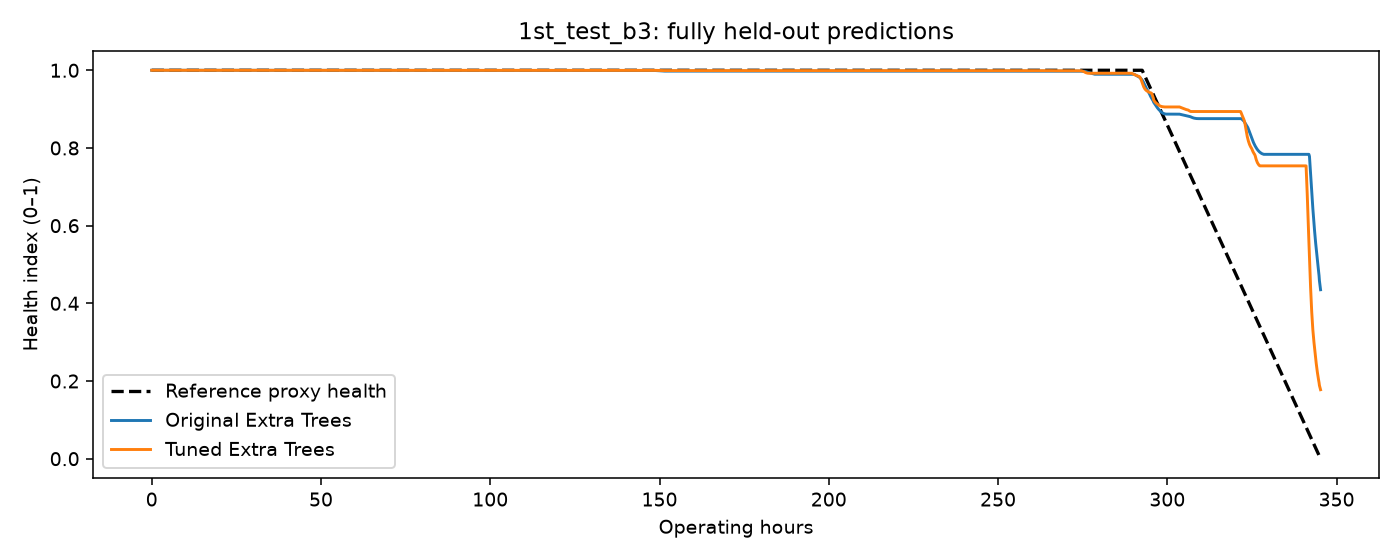

1st_test_b4


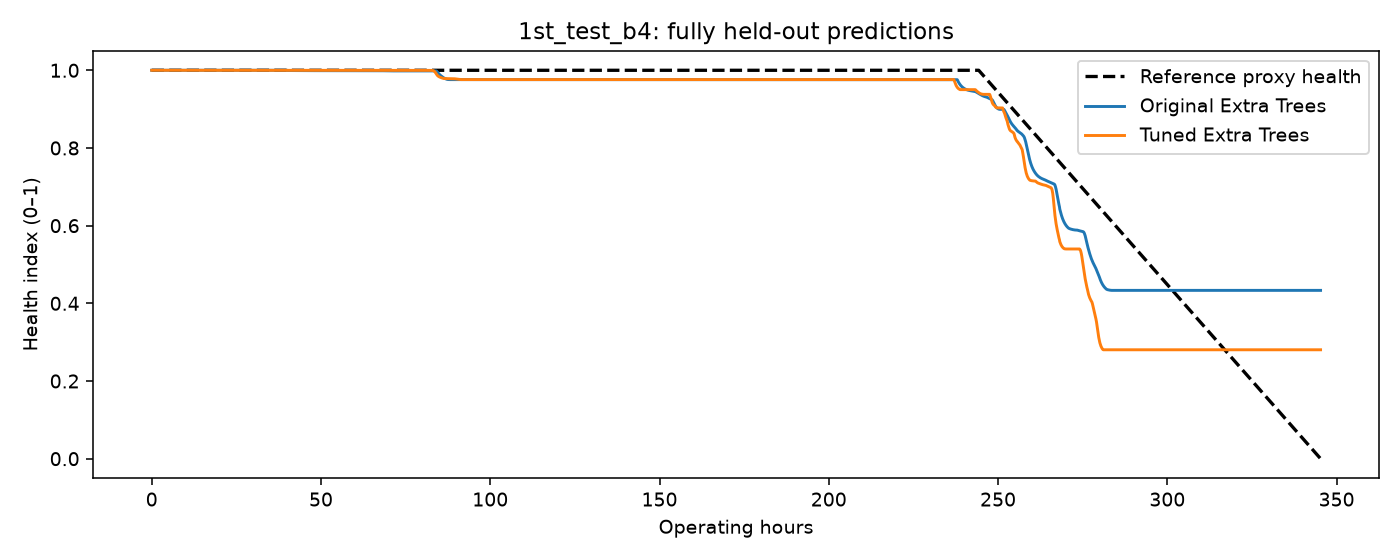

2nd_test_b1


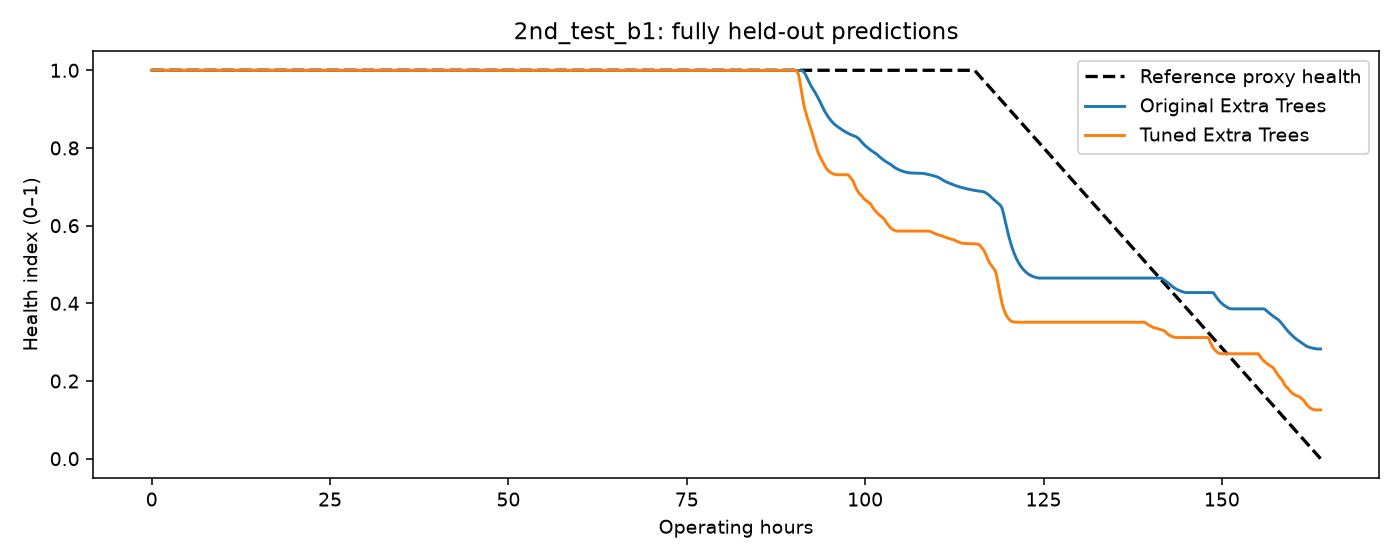

3rd_test_b3


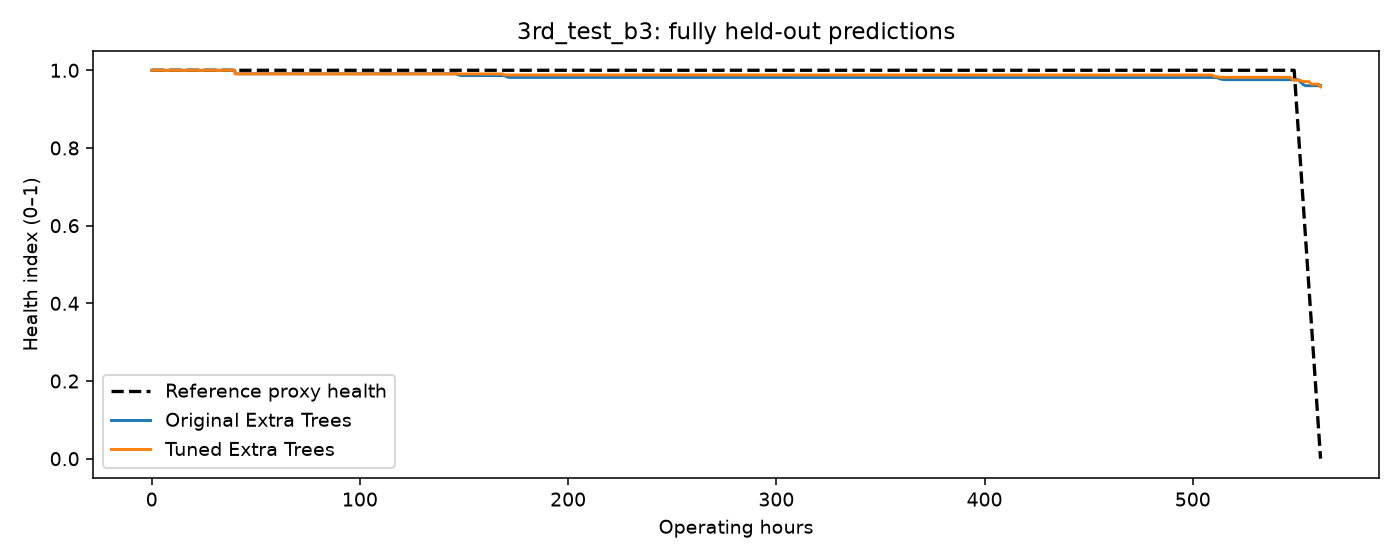

In [7]:
for path in sorted(OUT.glob('*_tuned_vs_baseline.png')):
    print(path.stem.replace('_tuned_vs_baseline',''))
    display(Image(filename=str(path)))


## 8. Visualize model trade-offs

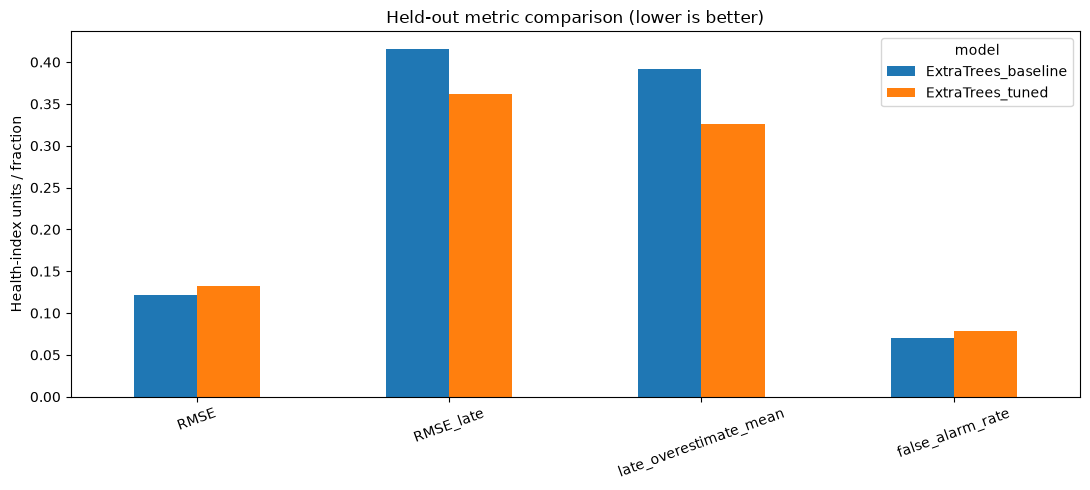

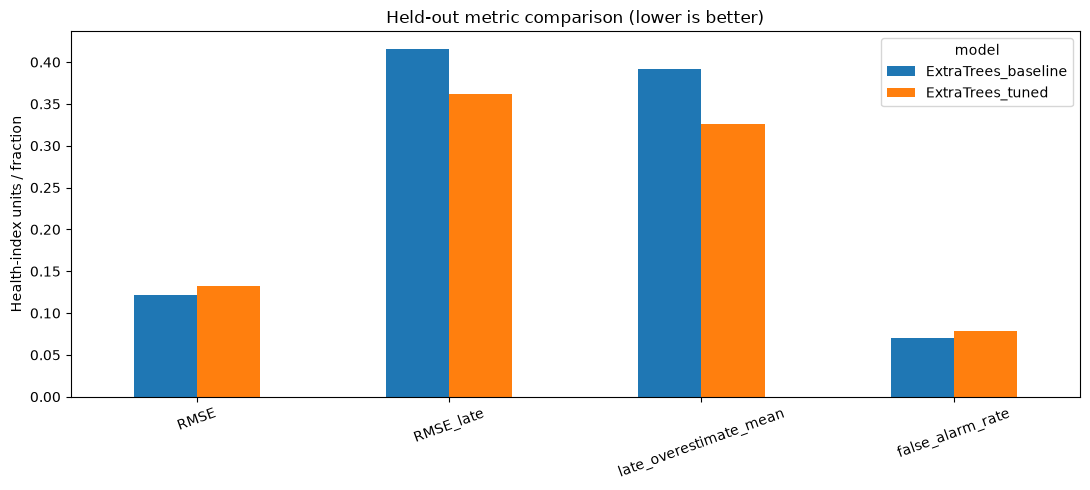

In [10]:
summary[['RMSE','RMSE_late','late_overestimate_mean','false_alarm_rate']].T.plot(
    kind='bar', figsize=(11,5), rot=20, title='Held-out metric comparison (lower is better)'
)
plt.ylabel('Health-index units / fraction')
plt.tight_layout()
plt.show()


In [9]:
%matplotlib inline

## 9. Interpretation and next steps

- **If tuned Extra Trees improves late-stage RMSE:** quantify how much, and whether false alarms worsen. This is an experimental improvement, **not confirmed generalization** beyond IMS.
- **If it does not:** report that LSTM and feature/weight tuning both failed to reliably beat Extra Trees. That is valuable negative evidence with only 3 independent experiments.
- **Additional bearing test:** your original `bearing_predictor2.py` has a `predict_many` helper to score the other bearings in each IMS test. Use it as a separate fault/false-alarm case study. Do **not** claim those additional sensor trajectories provide independent run-to-failure ground truth.
- **Group future work:** compare normalized errors across turbofan/battery/milling/bearing pipelines; only then decide on an API. The file `exploratory_final_model.joblib` is an experimental fit on all available failures and is **not** directly compatible with `bearing_predictor2.py` (different feature bundle).
- **Caution on selection:** do not repeatedly change hyperparameter grids based on the outer test scores; that would turn the test sets into validation sets. Collect new independent trajectories for stronger evidence.